# 2019 NYISO load and western-interface diagnostics

## tl;dr

The raw NYISO load audit reproduces all **96,360 zonal hour values** in both released input formats. The western flow errors remain substantial: **22.49% WAPE at Dysinger East** and **46.81% at West Central**. Their hourly errors move together (**r ≈ 0.994**), but this decomposition does not identify a unique cause.

This companion independently recomputes checks from saved CSVs and shows exploratory scenario results. **No load input, operating model, or source data is changed.** The scenarios are diagnostic alternatives, not verified corrections.

## Context & Methods

The baseline is the pinned released **57-bus 2019 DC model using the corrected interface operators**, over all 8,760 prepared local hour labels. Error means **simulated minus observed MW**. WAPE is `100 × sum(abs(error)) / sum(abs(observed))`; monthly bias is the mean signed error. The two interfaces overlap and must not be summed as independent statewide errors.

### Key Assumptions

- The original preparation averages repeated local-hour samples and fills missing local hours. It combines the autumn DST hour and interpolates the spring DST hour.
- Matching raw zonal load inputs does not validate the assumed allocation among individual buses.
- Common and differential error components are an algebraic accounting decomposition, not a causal identification.
- Counterfactual results use the same observed targets. Their source changes are hypotheses and are not established as true dispatch, topology, or thermal/AC operating corrections.

## Data

All inputs are existing files in `output/nygrid_2019_diagnostics`. Archive provenance is in `load_audit_archives.csv` and `load_audit_members.csv`; the public index is [NYISO Integrated Real-Time Actual Load](https://mis.nyiso.com/public/P-58Clist.htm). This notebook performs no network requests and no power-flow reruns.


In [1]:
from pathlib import Path
import hashlib
import json
import calendar
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'scripts/nygrid_2019_diagnostics').is_dir())
DATA = ROOT / 'output/nygrid_2019_diagnostics'
EXPECTED_HASHES = {'load_audit_summary.json': '1c5c6fef764ed1126ec5e4689eebf4483c87f1988fa249846b38eb72b1acb87d', 'load_audit_comparison.csv': 'af14aedfb12dba95724f64d3a5f59a69a498322f2269b44b154779671c35743e', 'load_audit_raw_rows.csv': 'b723cbbeff150c0b2632f9b5703b2c1ed70dbc1d9ad54358bdc35a8109cb98e8', 'load_audit_hourly_quality.csv': '92256d5d1c2af621c91151e25b202b3e619d024dbff390843e6e7649ef370abc', 'western_hourly.csv': 'd6a7bf2ade8ea4c168d1e4e8d56067a167e0a2b0dffacd644d5276783cbef095', 'western_interface_metrics.csv': '881e5ddd7b27776e978933bbc7fc4b9dcf76182ff9b5099f3b28188dab904a0b', 'western_summary.json': '73f4e2d98bfee780d8726a971403cdd0edeb6a861e92b8f6da88f89a15954c2e', 'counterfactual_hourly.csv': '900f6181e23b63bbf584bb9e5eb38fc4cf5b48d4fb65ab7be5030740c5d00d2b', 'counterfactual_metrics.csv': 'd5a059ddfca5c14bc64f49b6edc92109abd8d70f64d2133f958223a8c31e0a0b', 'counterfactual_summary.json': '4c60a4e6b28dc8e8df4541be5b88b10f34ff4abc0ee5ade6b9cf0496aebfa796'}
for name, expected in EXPECTED_HASHES.items():
    assert hashlib.sha256((DATA / name).read_bytes()).hexdigest() == expected, name
display(pd.DataFrame([{'Saved source': name, 'SHA-256 prefix': value[:16]}
                      for name, value in EXPECTED_HASHES.items()]))


,Saved source,SHA-256 prefix
0,load_audit_summary.json,1c5c6fef764ed112
1,load_audit_comparison.csv,af14aedfb12dba95
2,load_audit_raw_rows.csv,b723cbbeff150c0b
3,load_audit_hourly_quality.csv,92256d5d1c2af621
4,western_hourly.csv,d6a7bf2ade8ea4c1
5,western_interface_metrics.csv,881e5ddd7b27776e
6,western_summary.json,73f4e2d98bfee780
7,counterfactual_hourly.csv,900f6181e23b63bb
8,counterfactual_metrics.csv,d5a059ddfca5c14b
9,counterfactual_summary.json,4c60a4e6b28dc8e8


### Check the load-source comparison

Recompute differences from the saved numeric input columns, then reconcile raw-row, duplicate, and imputation counts with the source-audit summary. The original audit also exported the actual MATLAB table and checked it separately; the summary's maximum numerical discrepancy before CSV serialization was 2.27 × 10⁻¹³ MW.


In [2]:
load_summary = json.loads((DATA / 'load_audit_summary.json').read_text())
load_comparison = pd.read_csv(DATA / 'load_audit_comparison.csv')
raw_load = pd.read_csv(DATA / 'load_audit_raw_rows.csv',
                       usecols=['TimeStamp', 'TimeZone', 'ZoneName', 'Load'])
load_quality = pd.read_csv(DATA / 'load_audit_hourly_quality.csv',
                           usecols=['TimeStamp', 'ZoneName', 'Load_imputed'])
keys = ['TimeStamp', 'ZoneName']
assert len(load_comparison) == 8760 * 11
assert not load_comparison.duplicated(keys).any()
load_checks = []
for source in ['released_csv', 'released_mat']:
    error = (load_comparison['reconstructed_load_mw'] -
             load_comparison[f'{source}_load_mw']).to_numpy()
    assert np.isfinite(error).all()
    assert load_comparison[f'{source}_key_status'].eq('both').all()
    mismatches = int(np.count_nonzero(np.abs(error) > 1e-8))
    assert mismatches == load_summary[source.replace('released_', '') + '_comparison']['rows_above_tolerance_or_missing'] == 0
    load_checks.append({'Input format': source, 'Compared zone-hours': len(error),
                        'Differences above 1e-8 MW': mismatches,
                        'Max difference from saved values (MW)': np.max(np.abs(error))})

raw_groups = raw_load.groupby(keys).size()
counts = {'raw_rows': len(raw_load),
          'unique_raw_timestamp_zone_keys': len(raw_groups),
          'duplicate_timestamp_zone_groups': int(raw_groups.gt(1).sum()),
          'raw_missing_load_values': int(raw_load.Load.isna().sum()),
          'interpolated_hour_zone_keys': int(load_quality.Load_imputed.sum())}
for key, value in counts.items():
    assert value == load_summary[key], key
assert set(load_quality.loc[load_quality.Load_imputed, 'TimeStamp']) == {'2019-03-10 02:00:00'}
assert set(raw_groups[raw_groups.gt(1)].index.get_level_values('TimeStamp')) == {'2019-11-03 01:00:00'}
display(pd.DataFrame(load_checks).style.format({'Max difference from saved values (MW)': '{:.3g}'}))
display(pd.DataFrame({'Count': counts}).rename_axis('Check'))


,Input format,Compared zone-hours,Differences above 1e-8 MW,Max difference from saved values (MW)
0,released_csv,96360,0,0
1,released_mat,96360,0,0


,Count
Check,
raw_rows,96360
unique_raw_timestamp_zone_keys,96349
duplicate_timestamp_zone_groups,11
raw_missing_load_values,0
interpolated_hour_zone_keys,11


## Results

### Recompute western flow metrics

The calculations below use hourly simulated and observed values, independently of the saved metric routines. All 8,760 hours are retained. West Central has roughly half Dysinger East's mean absolute observed flow, so similar MW errors produce a substantially larger percentage error.


In [3]:
west = pd.read_csv(DATA / 'western_hourly.csv', parse_dates=['prepared_local_hour'])
assert len(west) == 8760 and west.prepared_local_hour.is_unique
assert west.hour_index.tolist() == list(range(1, 8761))
expected_times = pd.date_range('2019-01-01', '2019-12-31 23:00', freq='h')
assert np.array_equal(west.prepared_local_hour.to_numpy(), expected_times.to_numpy())

def metrics(simulated, observed):
    simulated, observed = np.asarray(simulated), np.asarray(observed)
    assert np.isfinite(simulated).all() and np.isfinite(observed).all()
    error = simulated - observed
    return {'hours': len(error), 'mae_mw': np.mean(np.abs(error)),
            'rmse_mw': np.sqrt(np.mean(error**2)),
            'bias_sim_minus_observed_mw': np.mean(error),
            'wape_pct': 100 * np.sum(np.abs(error)) / np.sum(np.abs(observed)),
            'mean_absolute_observed_mw': np.mean(np.abs(observed))}

baseline_rows = []
for name, prefix in [('Dysinger East', 'dysinger'), ('West Central', 'west_central')]:
    result = metrics(west[f'{prefix}_sim_mw'], west[f'{prefix}_observed_mw'])
    assert np.max(np.abs(west[f'{prefix}_error_mw'] -
                         (west[f'{prefix}_sim_mw'] - west[f'{prefix}_observed_mw']))) < 1e-8
    baseline_rows.append({'Interface': name, **result})
baseline = pd.DataFrame(baseline_rows).set_index('Interface')
saved_baseline = pd.read_csv(DATA / 'western_interface_metrics.csv').set_index('interface')
for name, row in baseline.iterrows():
    for metric in ['mae_mw', 'rmse_mw', 'bias_sim_minus_observed_mw', 'wape_pct']:
        assert abs(row[metric] - saved_baseline.loc[name, metric]) < 1e-8
display(baseline.rename(columns={'hours': 'Hours', 'mae_mw': 'MAE (MW)',
    'rmse_mw': 'RMSE (MW)', 'bias_sim_minus_observed_mw': 'Bias (MW)',
    'wape_pct': 'WAPE (%)', 'mean_absolute_observed_mw': 'Mean |observed| (MW)'}).style.format(precision=2))


,Hours,MAE (MW),RMSE (MW),Bias (MW),WAPE (%),Mean |observed| (MW)
Interface,,,,,,
Dysinger East,8760,209.92,261.15,51.93,22.49,933.21
West Central,8760,218.46,270.23,84.63,46.81,466.74


### Examine shared error and seasonality

For errors `e_D` and `e_W`, define the common component `c = (e_D + e_W)/2` and the differential half-component `d = (e_W − e_D)/2`. The identity `e_D² + e_W² = 2(c² + d²)` permits a squared-error decomposition without attributing a physical cause. Monthly averages show why a single annual bias correction is insufficient.


**Error correlation:** 0.993712. **Common-component share of pair squared error:** 99.33%. These are descriptive relationships, not unique causal attribution.

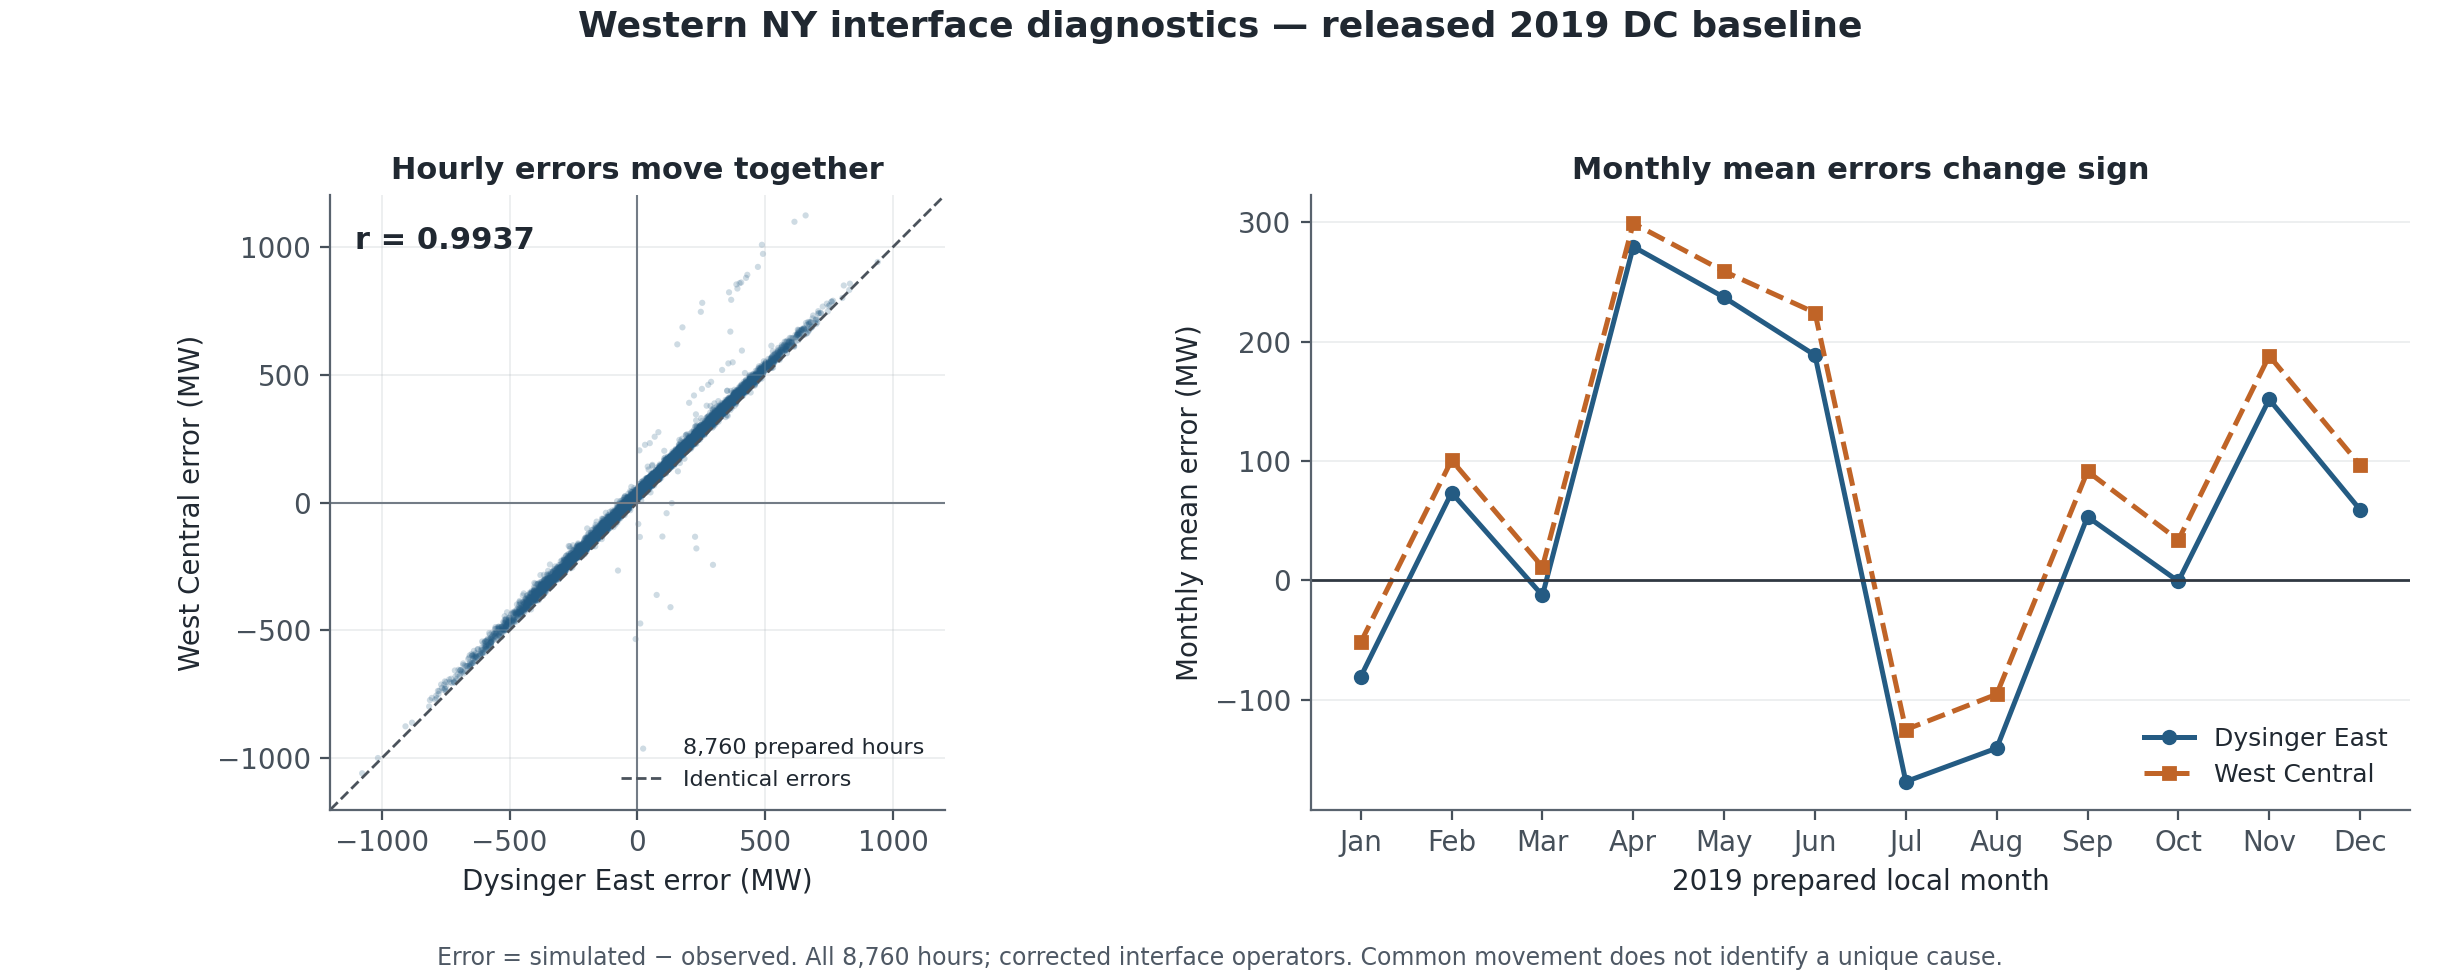

In [4]:
e_d = west.dysinger_sim_mw.to_numpy() - west.dysinger_observed_mw.to_numpy()
e_w = west.west_central_sim_mw.to_numpy() - west.west_central_observed_mw.to_numpy()
common, differential = (e_d + e_w) / 2, (e_w - e_d) / 2
correlation = np.corrcoef(e_d, e_w)[0, 1]
common_share = np.sum(common**2) / np.sum(common**2 + differential**2)
assert np.allclose(e_d**2 + e_w**2, 2 * (common**2 + differential**2), rtol=1e-12, atol=1e-8)
saved_summary = json.loads((DATA / 'western_summary.json').read_text())
assert abs(correlation - saved_summary['covariance_and_modes']['error_correlation']) < 1e-10
assert abs(common_share - saved_summary['covariance_and_modes']['common_fraction_pair_squared_error']) < 1e-10
monthly = pd.DataFrame({'Month': west.prepared_local_hour.dt.month,
                        'Dysinger East': e_d, 'West Central': e_w}).groupby('Month').mean()
display(Markdown(f'**Error correlation:** {correlation:.6f}. '
                 f'**Common-component share of pair squared error:** {100*common_share:.2f}%. '
                 'These are descriptive relationships, not unique causal attribution.'))

COLORS = {'Dysinger East': '#245B83', 'West Central': '#C06427'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.labelsize': 10, 'axes.titlesize': 11, 'axes.titleweight': 'semibold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#59636E', 'text.color': '#202831',
    'axes.labelcolor': '#202831', 'xtick.color': '#46505A', 'ytick.color': '#46505A',
    'figure.facecolor': 'white', 'savefig.facecolor': 'white', 'pdf.fonttype': 42})
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.9), gridspec_kw={'width_ratios': [1, 1.15]})
ax = axes[0]
extent = np.ceil(max(np.max(np.abs(e_d)), np.max(np.abs(e_w))) / 200) * 200
ax.scatter(e_d, e_w, s=5, alpha=0.22, color=COLORS['Dysinger East'],
           edgecolors='none', rasterized=True, label='8,760 prepared hours')
ax.plot([-extent, extent], [-extent, extent], ls='--', color='#4B535C', lw=1, label='Identical errors')
ax.axhline(0, color='#737C86', lw=.75)
ax.axvline(0, color='#737C86', lw=.75)
ax.set(xlim=(-extent, extent), ylim=(-extent, extent),
       xlabel='Dysinger East error (MW)', ylabel='West Central error (MW)',
       title='Hourly errors move together')
ax.set_aspect('equal', adjustable='box')
ax.text(.04, .95, f'r = {correlation:.4f}', transform=ax.transAxes, va='top',
        fontsize=11, fontweight='semibold')
ax.legend(loc='lower right', frameon=False, fontsize=8)
ax.grid(alpha=.25, color='#AAB2BB', lw=.6)
ax = axes[1]
for name, marker, style in [('Dysinger East', 'o', '-'), ('West Central', 's', '--')]:
    ax.plot(monthly.index, monthly[name], color=COLORS[name], marker=marker,
            linestyle=style, lw=1.8, markersize=4.5, label=name)
ax.axhline(0, color='#303842', lw=1)
ax.set(xticks=range(1, 13), xticklabels=[calendar.month_abbr[m] for m in range(1, 13)],
       ylabel='Monthly mean error (MW)', xlabel='2019 prepared local month',
       title='Monthly mean errors change sign')
ax.legend(frameon=False, fontsize=9, loc='lower right')
ax.grid(axis='y', alpha=.25, color='#AAB2BB', lw=.6)
fig.suptitle('Western NY interface diagnostics — released 2019 DC baseline', fontsize=13, fontweight='semibold', y=.99)
fig.text(.5, .015, 'Error = simulated − observed. All 8,760 hours; corrected interface operators. Common movement does not identify a unique cause.',
         ha='center', fontsize=8.5, color='#4E5864')
fig.tight_layout(rect=[0, .055, 1, .94], w_pad=3)
fig.savefig(DATA / 'western_diagnostics.png', dpi=200)
fig.savefig(DATA / 'western_diagnostics.pdf')
plt.close(fig)
display(Image(filename=str(DATA / 'western_diagnostics.png')))


### Check the counterfactual metric table

The following table reads the saved scenario metrics and checks both western interfaces against independently recomputed metrics from the scenario hourly CSV. Each scenario retains all 8,760 observed hours. These are paired diagnostics rather than calibrated improvements: changing a mean bias is not sufficient evidence that a scenario is more accurate.


In [5]:
counterfactual = pd.read_csv(DATA / 'counterfactual_metrics.csv')
counter_hours = pd.read_csv(DATA / 'counterfactual_hourly.csv', parse_dates=['timestamp'])
assert not counter_hours.duplicated(['scenario', 'timestamp']).any()
observations = west[['prepared_local_hour', 'dysinger_observed_mw', 'west_central_observed_mw']]
rechecked = []
for scenario, group in counter_hours.groupby('scenario', sort=False):
    joined = group.merge(observations, left_on='timestamp', right_on='prepared_local_hour',
                         how='outer', validate='one_to_one', indicator=True)
    assert len(joined) == 8760 and joined['_merge'].eq('both').all()
    for name, simcol, obscol in [('Dysinger East', 'Dysinger_sim_mw', 'dysinger_observed_mw'),
                                 ('West Central', 'WestCentral_sim_mw', 'west_central_observed_mw')]:
        recomputed = metrics(joined[simcol], joined[obscol])
        saved = counterfactual.loc[(counterfactual.scenario == scenario) & (counterfactual.interface == name)]
        assert len(saved) == 1
        for metric in ['mae_mw', 'rmse_mw', 'bias_sim_minus_observed_mw', 'wape_pct']:
            assert abs(recomputed[metric] - saved.iloc[0][metric]) < 1e-7
        rechecked.append({'scenario': scenario, 'interface': name, **recomputed})

names = {'released_57_baseline': 'Released 57-bus baseline',
         'monthly_EIA_hydro_pool': 'Monthly hydro pool scenario',
         'original_B_load_shares': 'Original B load shares',
         'conditional_shared_unit_once': 'Shared unit once (conditional)',
         'full_140_baseline': 'Full 140-bus baseline',
         'restored_raw_external_ties': 'Restored external ties scenario'}
selected = counterfactual[counterfactual.interface.isin(['Dysinger East', 'West Central'])]
table = selected.pivot(index='scenario', columns='interface', values=['wape_pct', 'bias_sim_minus_observed_mw'])
table = table.reindex(list(names)).rename(index=names)
table.columns = [f'{interface} — ' + ('WAPE (%)' if metric == 'wape_pct' else 'bias (MW)')
                 for metric, interface in table.columns]
table.index.name = 'Diagnostic scenario'
display(table.style.format(precision=2))
assert len(rechecked) == 12
display(Markdown('**All 12 western scenario/interface metric checks pass.** '
                 'The modified source scenarios shown here do not improve both western WAPEs. '
                 'Their physical validity remains unestablished; the full-network baseline is a separate model representation.'))


,Dysinger East — WAPE (%),West Central — WAPE (%),Dysinger East — bias (MW),West Central — bias (MW)
Diagnostic scenario,,,,
Released 57-bus baseline,22.49,46.81,51.93,84.63
Monthly hydro pool scenario,25.69,54.61,167.85,191.38
Original B load shares,22.50,46.82,52.20,84.91
Shared unit once (conditional),22.97,47.11,24.37,57.08
Full 140-bus baseline,22.49,46.81,51.91,84.62
Restored external ties scenario,38.98,71.67,-357.25,-324.54


**All 12 western scenario/interface metric checks pass.** The modified source scenarios shown here do not improve both western WAPEs. Their physical validity remains unestablished; the full-network baseline is a separate model representation.

## Takeaways

- The released **zonal load input and its source preparation are verified against raw NYISO archives**. They do not explain these discrepancies through a detectable raw-input mismatch.
- Similar western MW errors, combined with a smaller West Central observed-flow denominator, account for much of the percentage-error disparity.
- Strong shared error and seasonal sign changes describe the mismatch. **They do not uniquely identify hydro, other generation, external import landing, topology, or actual interface membership as the cause.**
- The scenario table tests alternative assumptions on the same hours. None is a verified source correction, and DC numerical balance is not bounded AC or thermal feasibility.

### Rebuild and inspect

From the repository root, rebuild this executed companion and its PNG/PDF figure:

```powershell
python scripts/nygrid_2019_diagnostics/build_notebook.py
```

The data-producing commands, if a separately authorized rerun is needed, are:

```powershell
python scripts/nygrid_2019_diagnostics/audit_raw_load.py --offline
```

The notebook itself only reads the saved comparison and diagnostic sources. It writes `western_diagnostics.png` and `western_diagnostics.pdf`; it does not redownload sources or rerun/change any operating model. The builder executes it top-to-bottom and saves the cell outputs in this file. Input SHA-256 checks prevent a silent rerun against changed inputs; rebuild the notebook to bind an intentionally refreshed evidence set.
